In [2]:
import sys

sys.path.append("../src")

import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from fuzzy import criar_sistema_fuzzy_queimadas
from utils import fix_seed, gerar_dados_sinteticos_queimadas


# Definir a classe de Inferência Bayesiana diretamente no notebook
class EnumerationInference:
    """Algoritmo INFERENCE-BY-ENUMERATION para P(X | e)."""

    def __init__(self, df):
        self.df = df
        self.variables = [
            "DiasSemChuva",
            "Temperatura",
            "Umidade",
            "RiscoFogo",
            "FocoQueimada",
        ]

    def _prob_conjunta(self, val_dict):
        query = " & ".join([f"({k} == {v})" for k, v in val_dict.items()])
        return len(self.df.query(query)) / len(self.df)

    def query(self, query_var, evidence):
        probs = {}
        for val in [0, 1]:
            extended_ev = evidence.copy()
            extended_ev[query_var] = val
            hidden_vars = [v for v in self.variables if v not in extended_ev]

            total_p = 0.0
            n_hidden = len(hidden_vars)
            for i in range(2**n_hidden):
                combination = format(i, f"0{n_hidden}b")
                full_dict = extended_ev.copy()
                for j, h_var in enumerate(hidden_vars):
                    full_dict[h_var] = int(combination[j])

                total_p += self._prob_conjunta(full_dict)

            probs[val] = total_p

        soma = sum(probs.values())
        return {k: v / (soma + 1e-12) for k, v in probs.items()}


fix_seed(42)
simulador_fuzzy = criar_sistema_fuzzy_queimadas()

print(
    "=== SISTEMA FUZZY DE MAMDANI E INFERÊNCIA BAYESIANA INICIALIZADOS ==="
)

=== SISTEMA FUZZY DE MAMDANI E INFERÊNCIA BAYESIANA INICIALIZADOS ===


In [3]:
# Definir 4 cenários ambientais para teste do pipeline completo
cenarios = [
    {
        "nome": "Cenário 1 (Seca Severa + Vento Forte)",
        "evidencia": {"DiasSemChuva": 1, "Temperatura": 1, "Umidade": 1},
        "vento_kmh": 42.0,
    },
    {
        "nome": "Cenário 2 (Seca Moderada + Vento Moderado)",
        "evidencia": {"DiasSemChuva": 1, "Temperatura": 1, "Umidade": 0},
        "vento_kmh": 22.0,
    },
    {
        "nome": "Cenário 3 (Condições Húmidas + Vento Fraco)",
        "evidencia": {"DiasSemChuva": 0, "Temperatura": 0, "Umidade": 0},
        "vento_kmh": 8.0,
    },
    {
        "nome": "Cenário 4 (Fronteira Ambígua - Alta Temp, Boa Umidade)",
        "evidencia": {"DiasSemChuva": 0, "Temperatura": 1, "Umidade": 0},
        "vento_kmh": 32.0,
    },
]

# Gerar e binarizar os dados para a inferência
df_raw = gerar_dados_sinteticos_queimadas(n_samples=1000)
df_bn = pd.DataFrame()
df_bn["DiasSemChuva"] = (df_raw["dias_sem_chuva"] >= 10).astype(int)
df_bn["Temperatura"] = (df_raw["temperatura_max"] >= 32).astype(int)
df_bn["Umidade"] = (df_raw["umidade_relativa"] <= 45).astype(int)
df_bn["RiscoFogo"] = (df_raw["risco_critico"] == 1).astype(int)
df_bn["FocoQueimada"] = (df_raw["risco_fogo"] >= 0.75).astype(int)

infer_bayes = EnumerationInference(df_bn)
resultados = []

for c in cenarios:
    # 1. Inferência Bayesiana da Etapa 5
    prob_bayes = infer_bayes.query("FocoQueimada", c["evidencia"])[1]

    # 2. Entradas no Sistema Fuzzy da Etapa 6
    simulador_fuzzy.input["prob_bayesiana"] = prob_bayes
    simulador_fuzzy.input["vento"] = c["vento_kmh"]
    simulador_fuzzy.compute()

    alerta_fuzzy = simulador_fuzzy.output["alerta"]
    decisao_hard = "ALERTA CRÍTICO" if prob_bayes >= 0.5 else "NORMAL"

    resultados.append({
        "Cenário": c["nome"],
        "P(Foco | Evidência)": round(prob_bayes, 4),
        "Vento (km/h)": c["vento_kmh"],
        "Nível Alerta Fuzzy (%)": round(alerta_fuzzy, 2),
        "Decisão Hard (0.5)": decisao_hard,
    })

df_res = pd.DataFrame(resultados)
print("=== RESULTADOS DA INTEGRAÇÃO DO PIPELINE COMPLETO ===")
print(df_res.to_string(index=False))

=== RESULTADOS DA INTEGRAÇÃO DO PIPELINE COMPLETO ===
                                               Cenário  P(Foco | Evidência)  Vento (km/h)  Nível Alerta Fuzzy (%) Decisão Hard (0.5)
                 Cenário 1 (Seca Severa + Vento Forte)               0.0071          42.0                   16.33             NORMAL
            Cenário 2 (Seca Moderada + Vento Moderado)               0.0000          22.0                   13.33             NORMAL
           Cenário 3 (Condições Húmidas + Vento Fraco)               0.0000           8.0                   13.33             NORMAL
Cenário 4 (Fronteira Ambígua - Alta Temp, Boa Umidade)               0.0000          32.0                   13.45             NORMAL


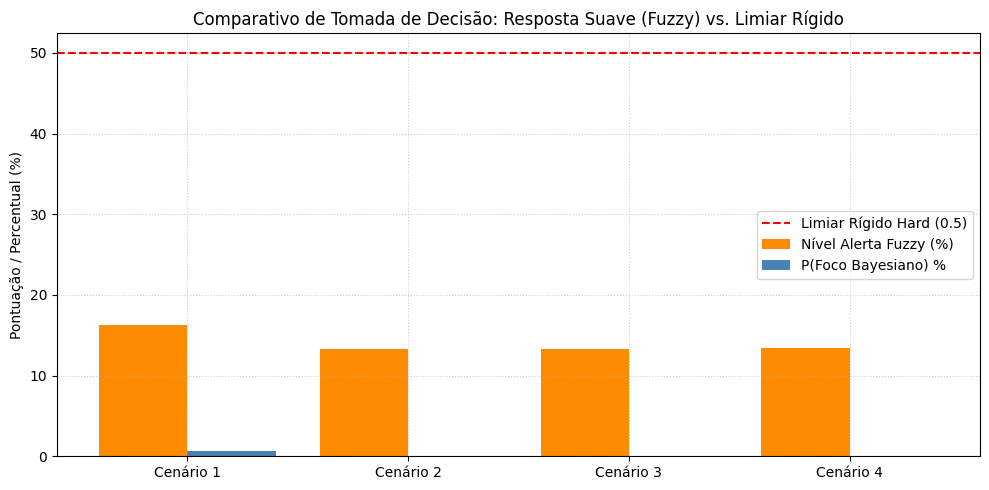

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))

x_labels = [f"Cenário {i+1}" for i in range(len(cenarios))]
alerta_valores = df_res["Nível Alerta Fuzzy (%)"].values
prob_valores = df_res["P(Foco | Evidência)"].values * 100

bar1 = ax.bar(
    np.arange(len(x_labels)) - 0.2,
    alerta_valores,
    0.4,
    label="Nível Alerta Fuzzy (%)",
    color="darkorange",
)
bar2 = ax.bar(
    np.arange(len(x_labels)) + 0.2,
    prob_valores,
    0.4,
    label="P(Foco Bayesiano) %",
    color="steelblue",
)

ax.axhline(
    50,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Limiar Rígido Hard (0.5)",
)
ax.set_xticks(np.arange(len(x_labels)))
ax.set_xticklabels(x_labels)
ax.set_ylabel("Pontuação / Percentual (%)")
ax.set_title(
    "Comparativo de Tomada de Decisão: Resposta Suave (Fuzzy) vs. Limiar Rígido"
)
ax.legend()
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()